<a href="https://colab.research.google.com/github/NisalJayaweera/EN3160-Fitting-and-Alignment/blob/main/notebooks/Q1_Sunflower_Blob_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/NisalJayaweera/EN3160-Fitting-and-Alignment.git
%cd EN3160-Fitting-and-Alignment
%pip install -q -r requirements.txt

Cloning into 'EN3160-Fitting-and-Alignment'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 44 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 1.71 MiB | 8.44 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/EN3160-Fitting-and-Alignment


In [2]:
from google.colab import files
from pathlib import Path
import zipfile

# Upload the ZIP file
uploaded = files.upload()

# Get the actual uploaded filename
zip_filename = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_filename is None:
    raise ValueError("Please upload a ZIP file.")

# Locate the uploaded ZIP
zip_path = Path(zip_filename).resolve()
print("ZIP file found at:", zip_path)

# Extract into the assignment repository
extract_path = Path(
    "/content/EN3160-Fitting-and-Alignment/images"
)
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("\nExtraction successful!")

# Display all extracted files
for file in extract_path.rglob("*"):
    if file.is_file():
        print(file)

Saving a2images.zip to a2images.zip
ZIP file found at: /content/EN3160-Fitting-and-Alignment/a2images.zip

Extraction successful!
/content/EN3160-Fitting-and-Alignment/images/a2images/flag.png
/content/EN3160-Fitting-and-Alignment/images/a2images/wadham.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/the_berry_farms_sunflower_field.jpeg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/AECC1.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/AECC2.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/AECC3.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/ADAD1.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/AECC4.jpg
/content/EN3160-Fitting-and-Alignment/images/a2images/pcbs/AAAA1.jpg


In [3]:
from pathlib import Path

repo = Path("/content/EN3160-Fitting-and-Alignment")

sunflower_files = list(
    (repo / "images").rglob(
        "the_berry_farms_sunflower_field.jpeg"
    )
)

print("Found:", sunflower_files)

Found: [PosixPath('/content/EN3160-Fitting-and-Alignment/images/a2images/the_berry_farms_sunflower_field.jpeg')]


In [4]:
%cd /content/EN3160-Fitting-and-Alignment

!python src/q1_blob_detection.py \
    --image images/a2images/the_berry_farms_sunflower_field.jpeg

/content/EN3160-Fitting-and-Alignment
Detected 561 blobs. Largest 10 by radius:
center=(297, 0), sigma=16.00, radius=22.63px, response=0.0638
center=(81, 155), sigma=16.00, radius=22.63px, response=0.0991
center=(28, 64), sigma=16.00, radius=22.63px, response=0.1462
center=(359, 136), sigma=14.00, radius=19.80px, response=0.1799
center=(221, 24), sigma=12.67, radius=17.91px, response=0.1315
center=(123, 359), sigma=12.00, radius=16.97px, response=0.1213
center=(269, 150), sigma=12.00, radius=16.97px, response=0.1821
center=(203, 153), sigma=12.00, radius=16.97px, response=0.1355
center=(334, 305), sigma=10.67, radius=15.08px, response=0.0893
center=(287, 19), sigma=10.00, radius=14.14px, response=0.0644
Saved results/q1/detected_circles.png and results/q1/circles.csv


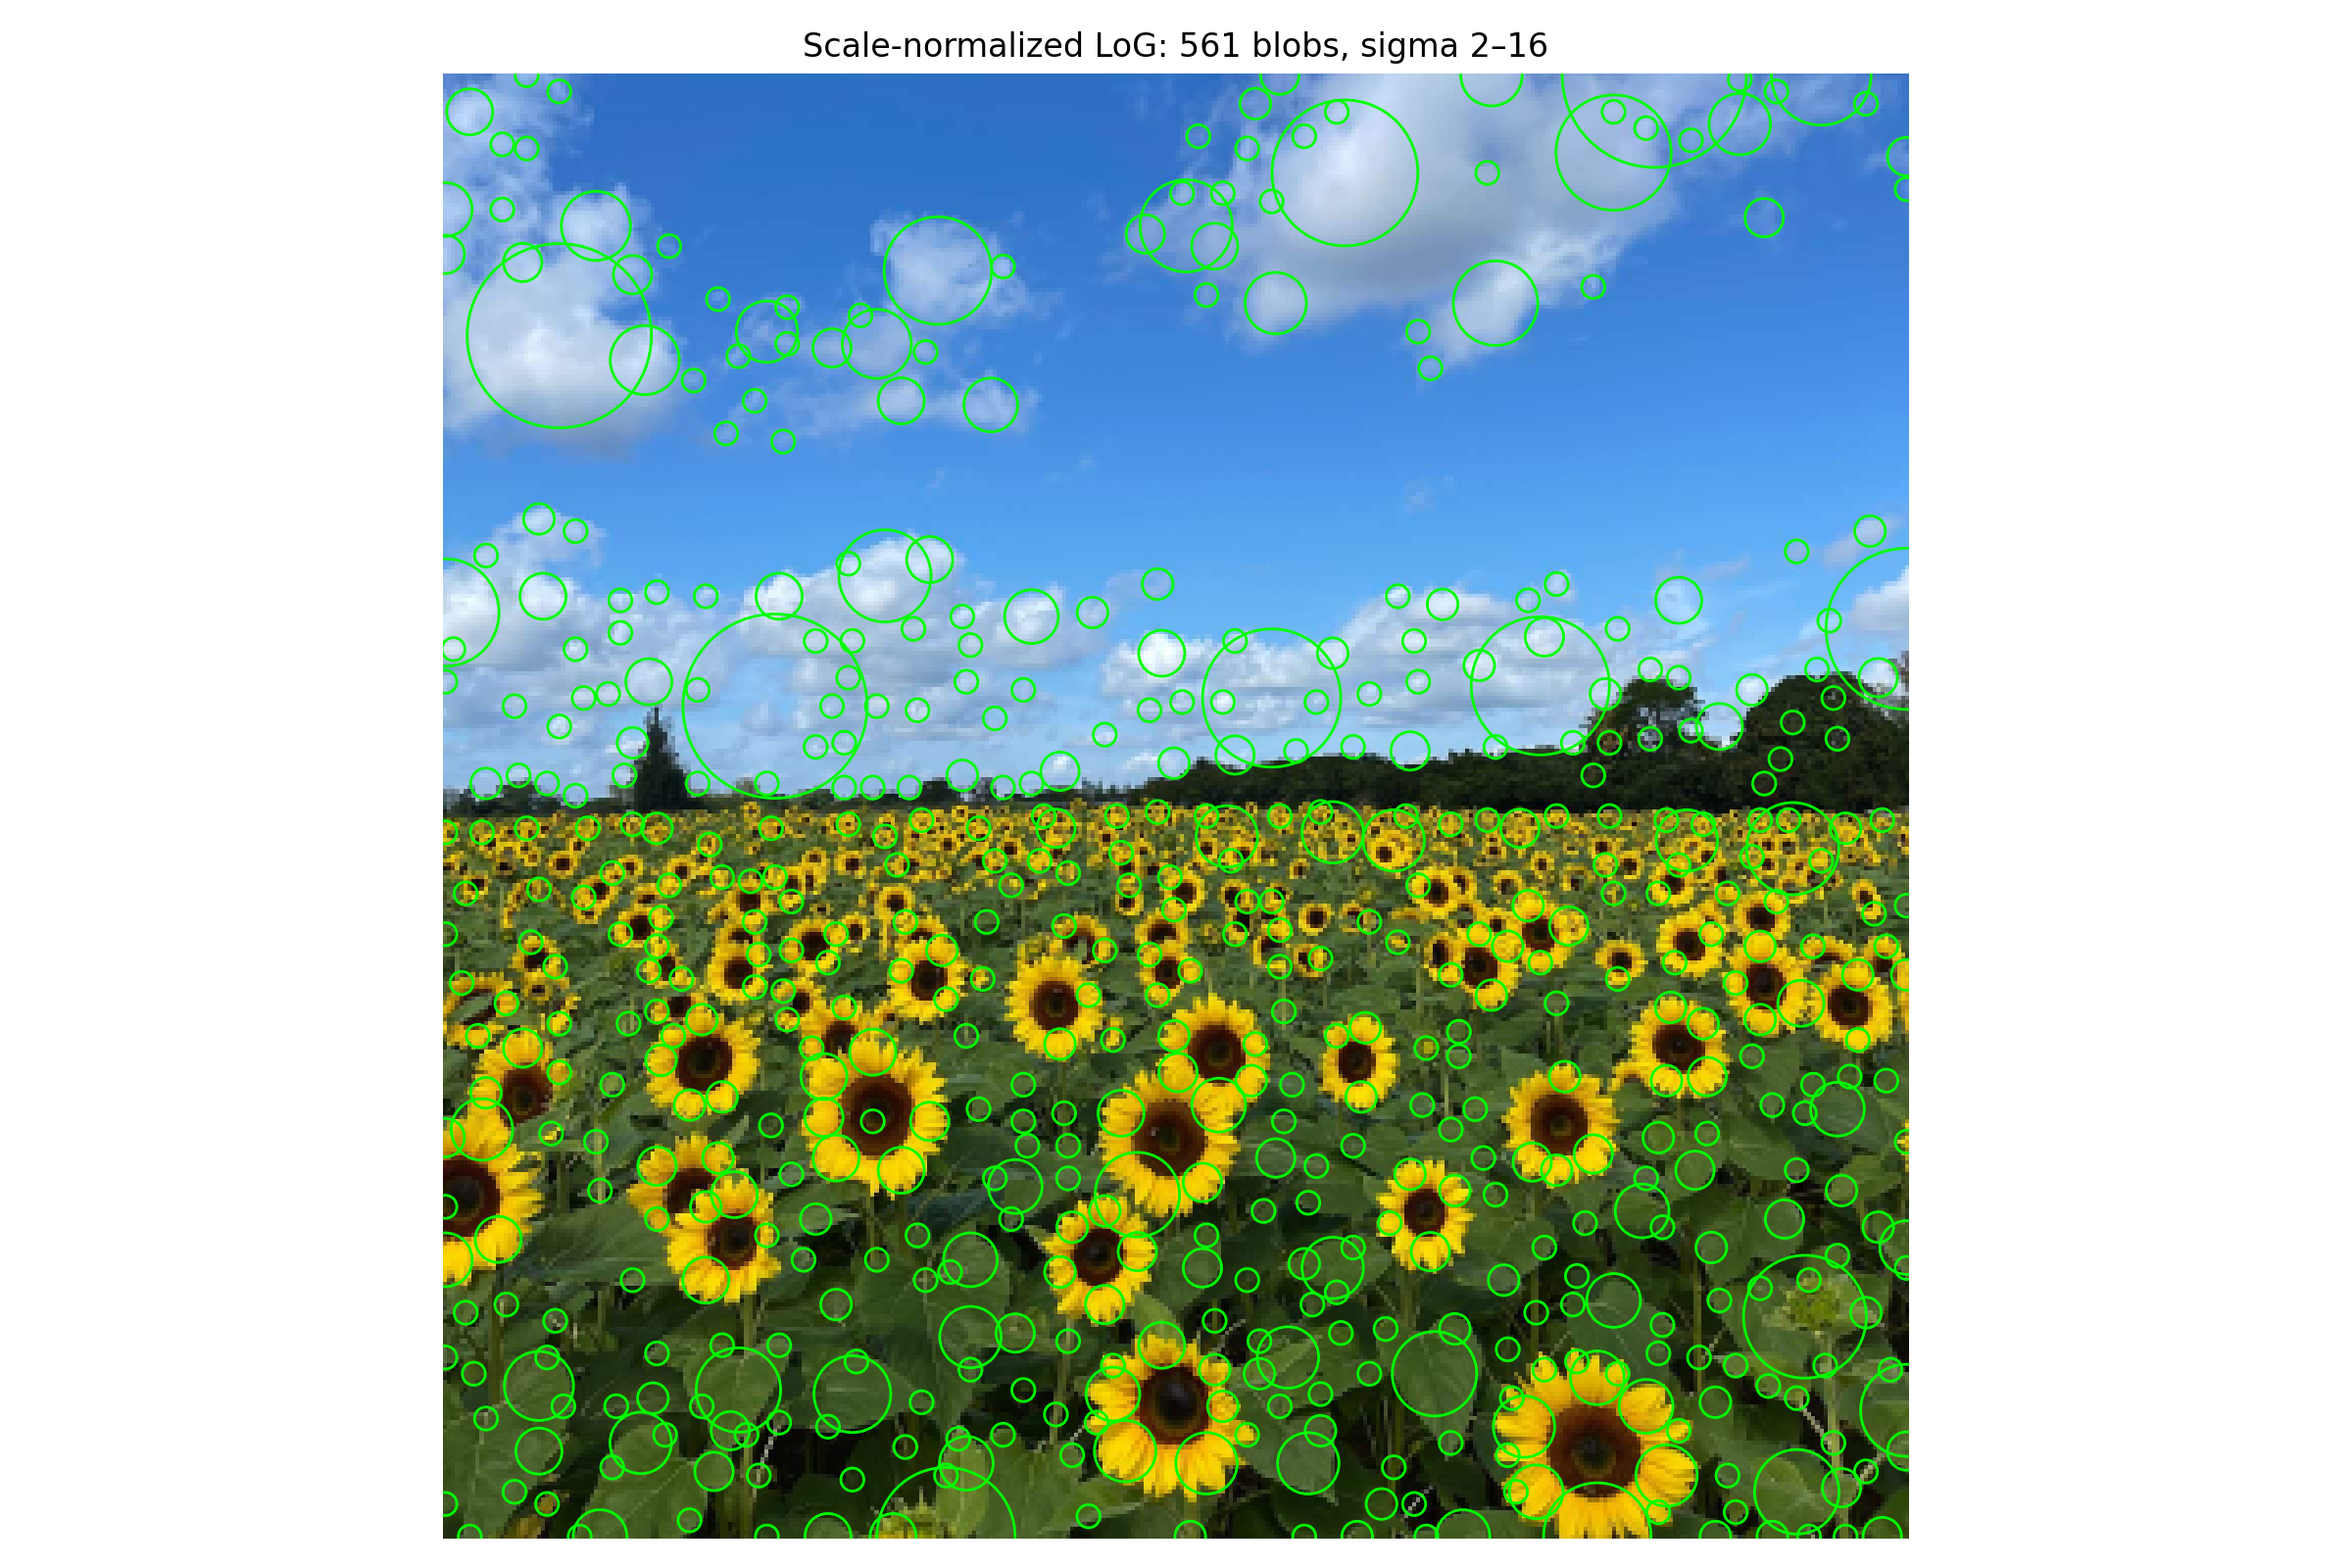

In [5]:
from IPython.display import Image, display

display(Image(
    filename="results/q1/detected_circles.png"
))

In [6]:
%cd /content/EN3160-Fitting-and-Alignment
!git pull origin main

/content/EN3160-Fitting-and-Alignment
From https://github.com/NisalJayaweera/EN3160-Fitting-and-Alignment
 * branch            main       -> FETCH_HEAD
Already up to date.


In [7]:
!python src/q1_blob_detection.py \
    --image images/a2images/the_berry_farms_sunflower_field.jpeg \
    --color-filter \
    --yellow-fraction 0.12

Detected 312 blobs. Largest 10 by radius:
center=(81, 155), sigma=16.00, radius=22.63px, response=0.0991
center=(123, 359), sigma=12.00, radius=16.97px, response=0.1213
center=(334, 305), sigma=10.67, radius=15.08px, response=0.0893
center=(283, 359), sigma=9.33, radius=13.20px, response=0.1805
center=(331, 190), sigma=8.00, radius=11.31px, response=0.1171
center=(359, 328), sigma=8.00, radius=11.31px, response=0.0616
center=(332, 348), sigma=7.33, radius=10.37px, response=0.0907
center=(72, 323), sigma=7.33, radius=10.37px, response=0.0695
center=(170, 275), sigma=7.33, radius=10.37px, response=0.1602
center=(23, 322), sigma=6.00, radius=8.49px, response=0.0649
Saved results/q1_filtered/detected_circles.png and results/q1_filtered/circles.csv


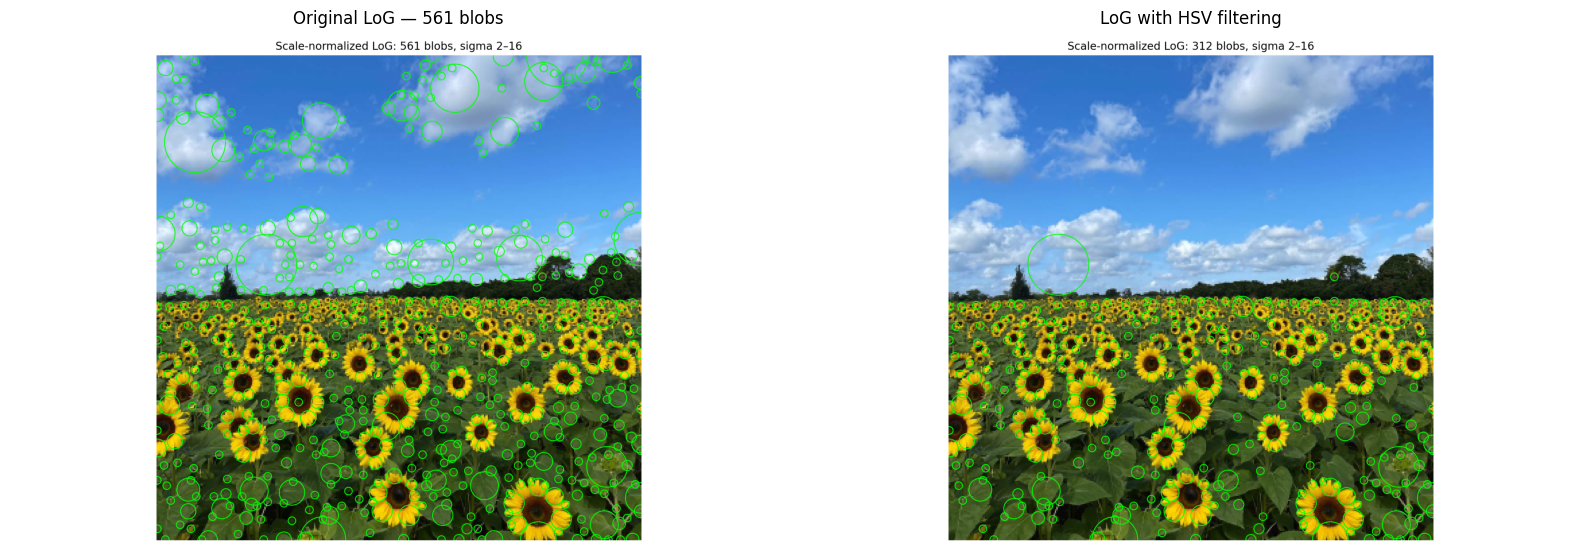

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

original = Image.open("results/q1/detected_circles.png")
improved = Image.open("results/q1_filtered/detected_circles.png")

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

axes[0].imshow(original)
axes[0].set_title("Original LoG — 561 blobs")
axes[0].axis("off")

axes[1].imshow(improved)
axes[1].set_title("LoG with HSV filtering")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Question 2: Line and Circle Fitting Using RANSAC

This experiment uses RANSAC to estimate a line and a circle
from a noisy point set containing observations from both models.

The line is estimated first using perpendicular-distance errors.
Its consensus points are then removed, and a circle is fitted
to the remaining points using radial-distance errors.

The RANSAC algorithms are implemented from scratch, and the
final models are refined using their respective consensus sets.

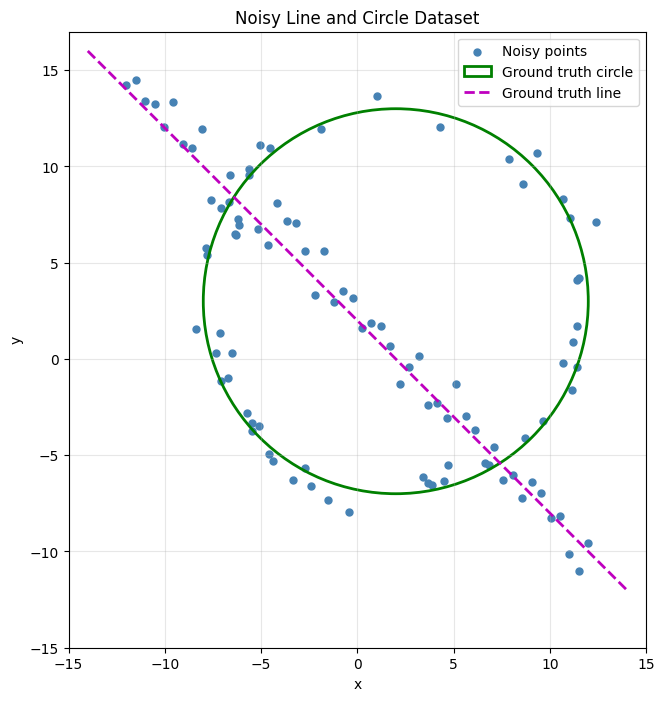

Total points: 100
Circle points: 50
Line points: 50


In [9]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Reproducibility
np.random.seed(0)

# Generate noisy circle points
N = 100
half_n = N // 2

r_gt = 10
x0_gt, y0_gt = 2, 3

s_circle = r_gt / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circle * np.random.randn(half_n)

x = x0_gt + (r_gt + n) * np.cos(t)
y = y0_gt + (r_gt + n) * np.sin(t)

X_circ = np.column_stack((x, y))

# Generate noisy line points
m_gt, b_gt = -1, 2
s_line = 1.0

x = np.linspace(-12, 12, half_n)
y = m_gt * x + b_gt + s_line * np.random.randn(half_n)

X_line = np.column_stack((x, y))

# Combined dataset
X = np.vstack((X_circ, X_line))

# Plot
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[:, 0], X[:, 1],
           color="steelblue", s=25, label="Noisy points")

circle_gt = plt.Circle(
    (x0_gt, y0_gt), r_gt,
    fill=False, color="green",
    linewidth=2, label="Ground truth circle"
)
ax.add_patch(circle_gt)

x_range = np.linspace(-14, 14, 300)
ax.plot(x_range, m_gt * x_range + b_gt,
        "m--", linewidth=2, label="Ground truth line")

ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Noisy Line and Circle Dataset")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Total points:", len(X))
print("Circle points:", len(X_circ))
print("Line points:", len(X_line))


In [10]:

def line_from_two_points(p1, p2):
    direction = p2 - p1
    normal = np.array([-direction[1], direction[0]])
    norm = np.linalg.norm(normal)

    if norm < 1e-12:
        return None

    normal = normal / norm
    a, b = normal
    d = np.dot(normal, p1)

    return np.array([a, b, d])


def line_errors(points, model):
    a, b, d = model
    return np.abs(points[:, 0] * a +
                  points[:, 1] * b - d)


def fit_line_tls(points):
    centroid = np.mean(points, axis=0)
    centered = points - centroid

    _, _, Vt = np.linalg.svd(centered)
    normal = Vt[-1]
    normal = normal / np.linalg.norm(normal)

    d = np.dot(normal, centroid)

    return np.array([normal[0], normal[1], d])


def ransac_line(points, threshold=0.8,
                iterations=3000, min_inliers=30, seed=42):

    rng = np.random.default_rng(seed)

    best_model = None
    best_sample_model = None
    best_sample_indices = None
    best_inliers = None
    best_count = 0
    best_error = np.inf

    for _ in range(iterations):
        indices = rng.choice(len(points), 2, replace=False)
        model = line_from_two_points(*points[indices])

        if model is None:
            continue

        errors = line_errors(points, model)
        inliers = errors < threshold

        count = np.sum(inliers)
        total_error = np.sum(errors[inliers] ** 2)

        if (count > best_count or
            (count == best_count and total_error < best_error)):

            best_count = count
            best_error = total_error
            best_sample_model = model
            best_sample_indices = indices
            best_inliers = inliers

    if best_count < min_inliers:
        raise RuntimeError("Insufficient line consensus")

    best_model = fit_line_tls(points[best_inliers])

    return {
        "model": best_model,
        "sample_model": best_sample_model,
        "sample_indices": best_sample_indices,
        "inliers": best_inliers,
        "count": best_count
    }


line_result = ransac_line(X)

a, b, d = line_result["model"]

print("Estimated line parameters:")
print(f"a = {a:.4f}")
print(f"b = {b:.4f}")
print(f"d = {d:.4f}")
print(f"Normal magnitude = {np.hypot(a, b):.6f}")
print(f"Number of line inliers = {line_result['count']}")


Estimated line parameters:
a = 0.7124
b = 0.7018
d = 1.4255
Normal magnitude = 1.000000
Number of line inliers = 41


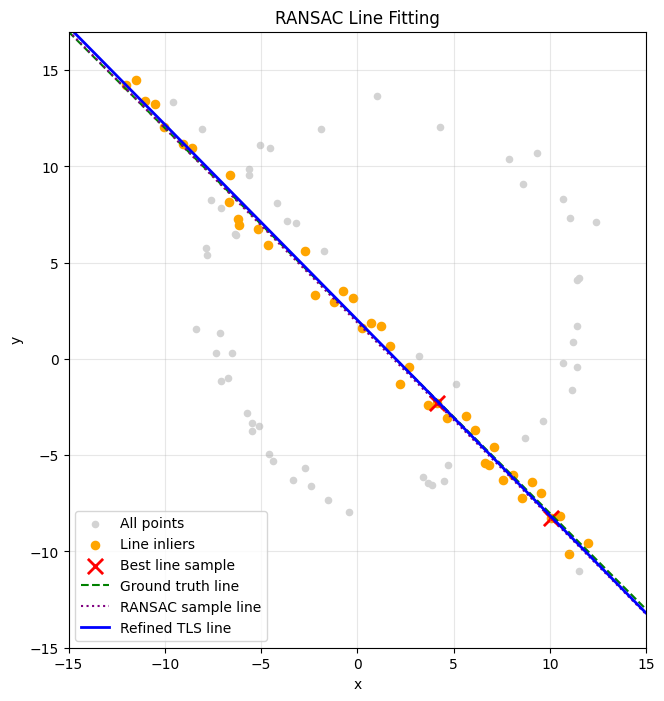

In [11]:

def plot_line(ax, model, x_values, **kwargs):
    a, b, d = model

    if abs(b) > 1e-10:
        y_values = (d - a * x_values) / b
        ax.plot(x_values, y_values, **kwargs)
    else:
        ax.axvline(d / a, **kwargs)


fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[:, 0], X[:, 1],
           s=20, color="lightgray", label="All points")

ax.scatter(
    X[line_result["inliers"], 0],
    X[line_result["inliers"], 1],
    s=35, color="orange", label="Line inliers"
)

sample = X[line_result["sample_indices"]]
ax.scatter(sample[:, 0], sample[:, 1],
           color="red", marker="x",
           s=120, linewidth=2, label="Best line sample")

x_values = np.linspace(-15, 15, 300)

ax.plot(x_values, m_gt * x_values + b_gt,
        "g--", label="Ground truth line")

plot_line(ax, line_result["sample_model"], x_values,
          color="purple", linestyle=":",
          label="RANSAC sample line")

plot_line(ax, line_result["model"], x_values,
          color="blue", linewidth=2,
          label="Refined TLS line")

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_aspect("equal")
ax.set_title("RANSAC Line Fitting")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


Total original points: 100
Line inliers removed: 41
Remaining points: 59


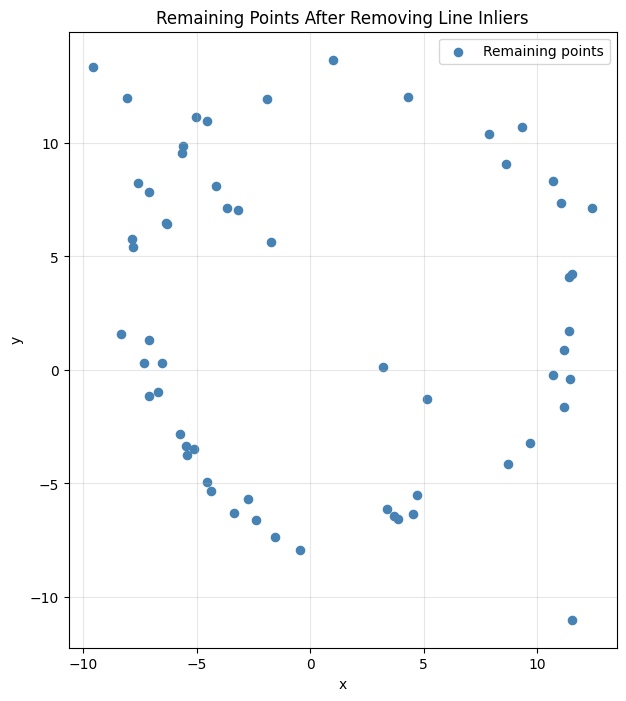

In [12]:

# Remove the line consensus points
line_inlier_mask = line_result["inliers"]

X_remaining = X[~line_inlier_mask]

print("Total original points:", len(X))
print("Line inliers removed:", np.sum(line_inlier_mask))
print("Remaining points:", len(X_remaining))

# Visualize remaining points
plt.figure(figsize=(8, 8))

plt.scatter(
    X_remaining[:, 0],
    X_remaining[:, 1],
    color="steelblue",
    s=35,
    label="Remaining points"
)

plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Remaining Points After Removing Line Inliers")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [13]:

def circle_from_three_points(p1, p2, p3):
    """
    Estimate a circle passing through three points.
    Returns (xc, yc, r), or None for collinear points.
    """
    A = 2 * np.array([
        p2 - p1,
        p3 - p1
    ])

    B = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)

    if not np.isfinite(radius):
        return None

    return np.array([center[0], center[1], radius])


def circle_errors(points, model):
    xc, yc, r = model

    distances = np.sqrt(
        (points[:, 0] - xc)**2 +
        (points[:, 1] - yc)**2
    )

    return np.abs(distances - r)


def fit_circle_least_squares(points, initial_model):
    """
    Refine the circle by minimizing squared radial errors.
    """
    def objective(params):
        errors = circle_errors(points, params)
        return np.sum(errors**2)

    result = minimize(
        objective,
        initial_model,
        method="L-BFGS-B",
        bounds=[
            (None, None),
            (None, None),
            (1e-6, None)
        ]
    )

    if not result.success:
        raise RuntimeError(
            f"Circle optimization failed: {result.message}"
        )

    return result.x


def ransac_circle(points, threshold=1.0,
                  iterations=5000,
                  min_inliers=25,
                  seed=42):

    rng = np.random.default_rng(seed)

    best_sample_model = None
    best_sample_indices = None
    best_inliers = None
    best_count = 0
    best_error = np.inf

    for _ in range(iterations):

        indices = rng.choice(
            len(points), 3, replace=False
        )

        sample = points[indices]

        model = circle_from_three_points(
            sample[0], sample[1], sample[2]
        )

        if model is None:
            continue

        errors = circle_errors(points, model)
        inliers = errors < threshold

        count = np.sum(inliers)
        total_error = np.sum(errors[inliers]**2)

        if (count > best_count or
            (count == best_count and
             total_error < best_error)):

            best_count = count
            best_error = total_error
            best_sample_model = model
            best_sample_indices = indices
            best_inliers = inliers.copy()

    if best_count < min_inliers:
        raise RuntimeError(
            "Insufficient circle consensus"
        )

    refined_model = fit_circle_least_squares(
        points[best_inliers],
        best_sample_model
    )

    return {
        "model": refined_model,
        "sample_model": best_sample_model,
        "sample_indices": best_sample_indices,
        "inliers": best_inliers,
        "count": best_count
    }


# Run circle RANSAC on remaining points
circle_result = ransac_circle(X_remaining)

xc, yc, r = circle_result["model"]

print("Estimated circle parameters:")
print(f"Center x = {xc:.4f}")
print(f"Center y = {yc:.4f}")
print(f"Radius   = {r:.4f}")
print(f"Circle inliers = {circle_result['count']}")


Estimated circle parameters:
Center x = 1.9751
Center y = 3.0746
Radius   = 9.9363
Circle inliers = 46


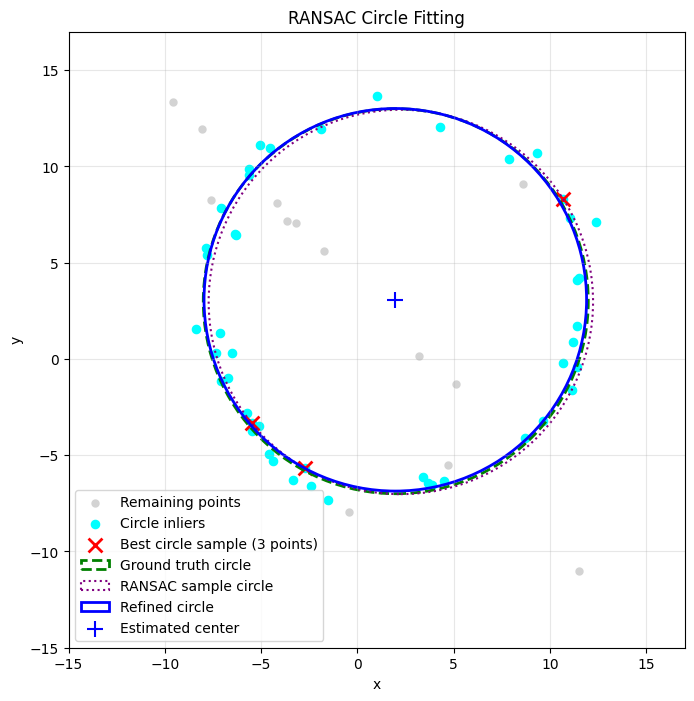

In [14]:

fig, ax = plt.subplots(figsize=(8, 8))

# Remaining points
ax.scatter(
    X_remaining[:, 0],
    X_remaining[:, 1],
    s=25,
    color="lightgray",
    label="Remaining points"
)

# Circle inliers
circle_inliers = X_remaining[circle_result["inliers"]]

ax.scatter(
    circle_inliers[:, 0],
    circle_inliers[:, 1],
    s=35,
    color="cyan",
    label="Circle inliers"
)

# Best RANSAC sample
sample = X_remaining[circle_result["sample_indices"]]

ax.scatter(
    sample[:, 0],
    sample[:, 1],
    s=100,
    color="red",
    marker="x",
    linewidth=2,
    label="Best circle sample (3 points)"
)

# Ground truth circle
gt_circle = plt.Circle(
    (x0_gt, y0_gt),
    r_gt,
    fill=False,
    edgecolor="green",
    linewidth=2,
    linestyle="--",
    label="Ground truth circle"
)
ax.add_patch(gt_circle)

# Circle from best RANSAC sample
sx, sy, sr = circle_result["sample_model"]

sample_circle = plt.Circle(
    (sx, sy),
    sr,
    fill=False,
    edgecolor="purple",
    linewidth=1.5,
    linestyle=":",
    label="RANSAC sample circle"
)
ax.add_patch(sample_circle)

# Refined circle
fitted_circle = plt.Circle(
    (xc, yc),
    r,
    fill=False,
    edgecolor="blue",
    linewidth=2,
    label="Refined circle"
)
ax.add_patch(fitted_circle)

ax.scatter(
    [xc], [yc],
    marker="+",
    s=120,
    color="blue",
    label="Estimated center"
)

ax.set_xlim(-15, 17)
ax.set_ylim(-15, 17)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Circle Fitting")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


In [15]:

print("Circle Parameter Comparison")
print("-" * 48)
print(f"{'Parameter':<15}{'Ground Truth':<15}{'Estimated':<15}")
print("-" * 48)

print(f"{'Center X':<15}{x0_gt:<15.4f}{xc:<15.4f}")
print(f"{'Center Y':<15}{y0_gt:<15.4f}{yc:<15.4f}")
print(f"{'Radius':<15}{r_gt:<15.4f}{r:<15.4f}")

center_error = np.linalg.norm(
    np.array([xc, yc]) - np.array([x0_gt, y0_gt])
)

radius_error = abs(r - r_gt)

print("\nEstimation Errors")
print(f"Center error: {center_error:.4f}")
print(f"Radius error: {radius_error:.4f}")

# Radial RMSE on the RANSAC consensus
inlier_errors = circle_errors(
    circle_inliers, circle_result["model"]
)

rmse = np.sqrt(np.mean(inlier_errors**2))

print(f"Circle inlier RMSE: {rmse:.4f}")


Circle Parameter Comparison
------------------------------------------------
Parameter      Ground Truth   Estimated      
------------------------------------------------
Center X       2.0000         1.9751         
Center Y       3.0000         3.0746         
Radius         10.0000        9.9363         

Estimation Errors
Center error: 0.0787
Radius error: 0.0637
Circle inlier RMSE: 0.5281


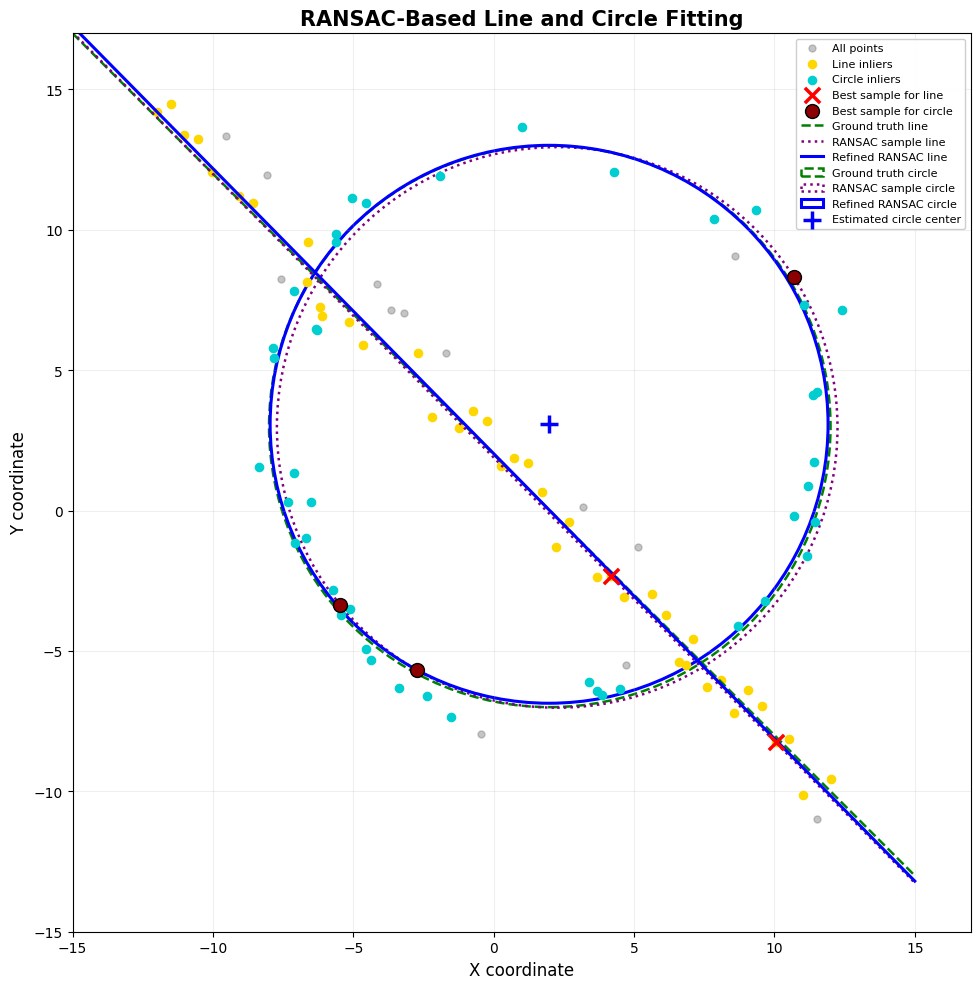

In [16]:

# ============================================
# Task 2(c): Combined RANSAC Visualization
# ============================================

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Original noisy points
ax.scatter(
    X[:, 0], X[:, 1],
    s=25, color="gray", alpha=0.45,
    label="All points", zorder=1
)

# 2. Line inliers
line_inliers = X[line_result["inliers"]]

ax.scatter(
    line_inliers[:, 0], line_inliers[:, 1],
    s=35, color="gold",
    label="Line inliers", zorder=2
)

# 3. Circle inliers
circle_inliers = X_remaining[circle_result["inliers"]]

ax.scatter(
    circle_inliers[:, 0], circle_inliers[:, 1],
    s=35, color="darkturquoise",
    label="Circle inliers", zorder=3
)

# 4. Best RANSAC sample for line
line_sample = X[line_result["sample_indices"]]

ax.scatter(
    line_sample[:, 0], line_sample[:, 1],
    s=120, color="red", marker="x",
    linewidth=2.5,
    label="Best sample for line", zorder=6
)

# 5. Best RANSAC sample for circle
circle_sample = X_remaining[circle_result["sample_indices"]]

ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    s=100, color="darkred", marker="o",
    edgecolor="black",
    label="Best sample for circle", zorder=6
)

# 6. Ground truth line
x_values = np.linspace(-15, 15, 400)

ax.plot(
    x_values,
    m_gt * x_values + b_gt,
    color="green", linestyle="--",
    linewidth=1.8,
    label="Ground truth line"
)

# 7. Line from best RANSAC sample
plot_line(
    ax,
    line_result["sample_model"],
    x_values,
    color="purple", linestyle=":",
    linewidth=1.8,
    label="RANSAC sample line"
)

# 8. Refined line using TLS
plot_line(
    ax,
    line_result["model"],
    x_values,
    color="blue",
    linewidth=2.2,
    label="Refined RANSAC line"
)

# 9. Ground truth circle
ground_truth_circle = plt.Circle(
    (x0_gt, y0_gt),
    r_gt,
    fill=False,
    edgecolor="green",
    linestyle="--",
    linewidth=1.8,
    label="Ground truth circle"
)
ax.add_patch(ground_truth_circle)

# 10. Circle from best RANSAC sample
sx, sy, sr = circle_result["sample_model"]

sample_circle = plt.Circle(
    (sx, sy),
    sr,
    fill=False,
    edgecolor="purple",
    linestyle=":",
    linewidth=1.8,
    label="RANSAC sample circle"
)
ax.add_patch(sample_circle)

# 11. Refined circle
xc, yc, r = circle_result["model"]

refined_circle = plt.Circle(
    (xc, yc),
    r,
    fill=False,
    edgecolor="blue",
    linewidth=2.2,
    label="Refined RANSAC circle"
)
ax.add_patch(refined_circle)

# 12. Estimated circle center
ax.scatter(
    xc, yc,
    marker="+", s=180,
    linewidth=2.5,
    color="blue",
    label="Estimated circle center",
    zorder=7
)

# Figure formatting
ax.set_xlim(-15, 17)
ax.set_ylim(-15, 17)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("X coordinate", fontsize=12)
ax.set_ylabel("Y coordinate", fontsize=12)

ax.set_title(
    "RANSAC-Based Line and Circle Fitting",
    fontsize=15, fontweight="bold"
)

ax.grid(True, alpha=0.2)
ax.legend(loc="upper right", fontsize=8, framealpha=0.95)

plt.tight_layout()

# Save for LaTeX report
plt.savefig(
    "Q2_RANSAC_Combined_Result.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:

# ============================================
# Quantitative Evaluation
# ============================================

# Ground truth normalized line
gt_normal = np.array([-m_gt, 1.0])
gt_normal /= np.linalg.norm(gt_normal)
gt_d = b_gt / np.sqrt(m_gt**2 + 1)

# Estimated line
a_est, b_est, d_est = line_result["model"]

# Account for sign ambiguity
estimated_normal = np.array([a_est, b_est])

if np.dot(estimated_normal, gt_normal) < 0:
    estimated_normal = -estimated_normal
    d_est = -d_est

# Angular error between normals
cos_angle = np.clip(
    np.dot(estimated_normal, gt_normal), -1, 1
)
angular_error = np.degrees(np.arccos(cos_angle))

# Perpendicular distance parameter error
distance_error = abs(d_est - gt_d)

# Circle parameter errors
xc, yc, r = circle_result["model"]

center_error = np.hypot(xc - x0_gt, yc - y0_gt)
radius_error = abs(r - r_gt)

print("=" * 50)
print("RANSAC MODEL EVALUATION")
print("=" * 50)

print("\nLINE FITTING")
print(f"Line inliers       : {line_result['count']}")
print(f"Angular error      : {angular_error:.4f} degrees")
print(f"Distance error     : {distance_error:.4f}")

print("\nCIRCLE FITTING")
print(f"Circle inliers     : {circle_result['count']}")
print(f"Center error       : {center_error:.4f}")
print(f"Radius error       : {radius_error:.4f}")

print("\nMODEL PARAMETERS")
print(f"Estimated line     : {a_est:.4f}x + "
      f"{b_est:.4f}y = {line_result['model'][2]:.4f}")
print(f"Estimated circle   : center=({xc:.4f}, {yc:.4f}), "
      f"radius={r:.4f}")


RANSAC MODEL EVALUATION

LINE FITTING
Line inliers       : 41
Angular error      : 0.4318 degrees
Distance error     : 0.0113

CIRCLE FITTING
Circle inliers     : 46
Center error       : 0.0787
Radius error       : 0.0637

MODEL PARAMETERS
Estimated line     : 0.7124x + 0.7018y = 1.4255
Estimated circle   : center=(1.9751, 3.0746), radius=9.9363


In [18]:

# ============================================
# Task 2(d): Circle-First RANSAC
# ============================================

# Step 1: Fit circle to the entire dataset
circle_first_result = ransac_circle(
    X,
    threshold=1.0,
    iterations=5000,
    min_inliers=25,
    seed=42
)

# Step 2: Remove circle consensus
circle_first_mask = circle_first_result["inliers"]
X_after_circle = X[~circle_first_mask]

# Step 3: Fit line to remaining points
line_second_result = ransac_line(
    X_after_circle,
    threshold=0.8,
    iterations=3000,
    min_inliers=30,
    seed=42
)

# Extract parameters
xc_cf, yc_cf, r_cf = circle_first_result["model"]
a_cf, b_cf, d_cf = line_second_result["model"]

print("CIRCLE-FIRST FITTING RESULTS")
print("=" * 45)

print("\nCircle estimated first:")
print(f"Center = ({xc_cf:.4f}, {yc_cf:.4f})")
print(f"Radius = {r_cf:.4f}")
print(f"Inliers = {circle_first_result['count']}")

print("\nLine estimated second:")
print(f"a = {a_cf:.4f}")
print(f"b = {b_cf:.4f}")
print(f"d = {d_cf:.4f}")
print(f"Inliers = {line_second_result['count']}")


CIRCLE-FIRST FITTING RESULTS

Circle estimated first:
Center = (1.8693, 3.1217)
Radius = 9.8279
Inliers = 54

Line estimated second:
a = -0.7195
b = -0.6945
d = -1.4827
Inliers = 36


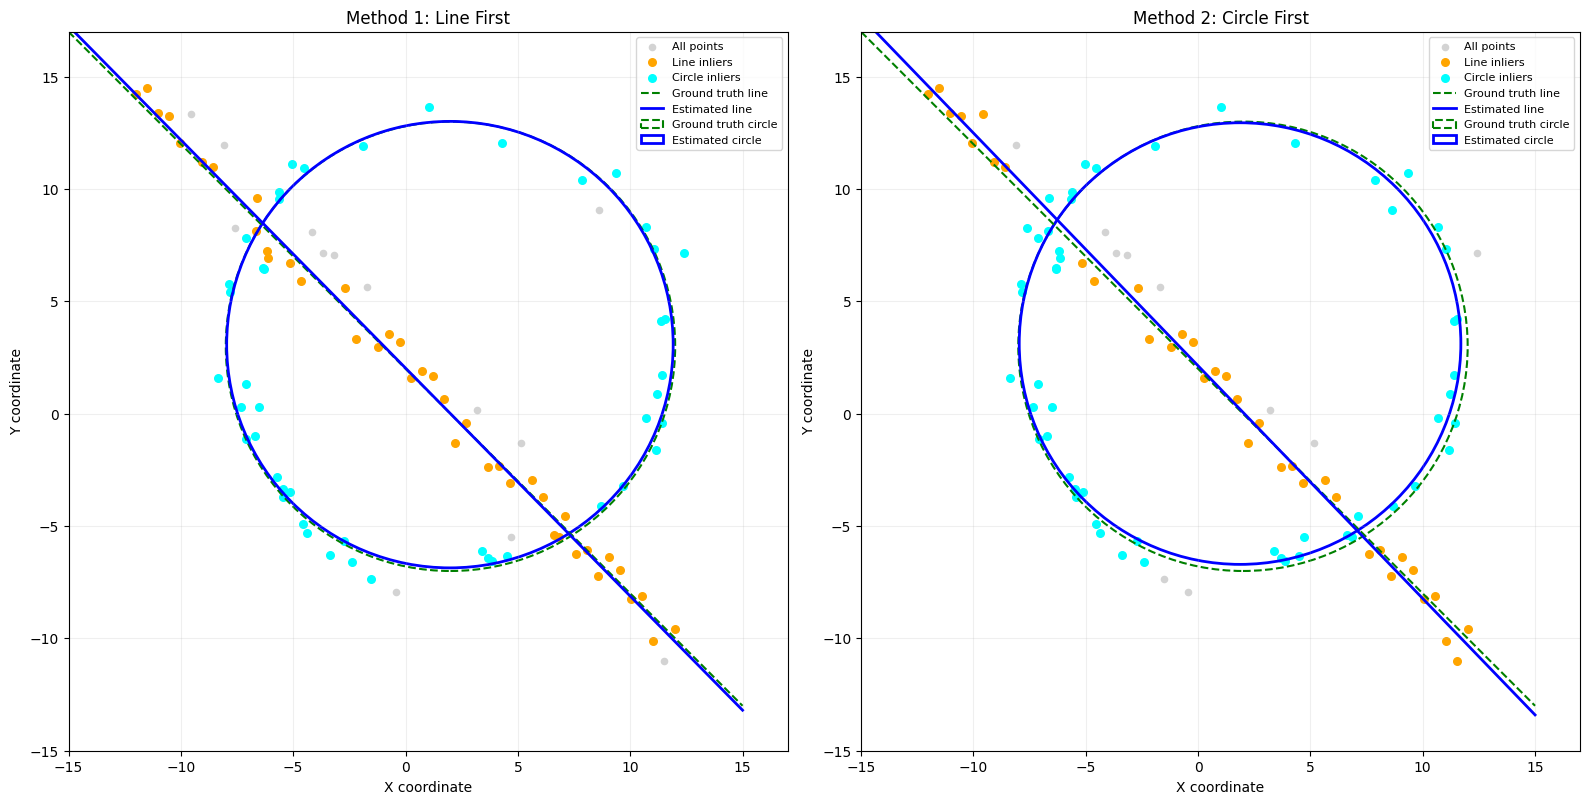

In [19]:

# ============================================
# Comparison: Line First vs Circle First
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

def plot_fitting_result(ax, points, line_model,
                        circle_model, title,
                        line_points, circle_points):

    ax.scatter(
        points[:, 0], points[:, 1],
        s=20, color="lightgray",
        label="All points"
    )

    ax.scatter(
        line_points[:, 0], line_points[:, 1],
        s=30, color="orange",
        label="Line inliers"
    )

    ax.scatter(
        circle_points[:, 0], circle_points[:, 1],
        s=30, color="cyan",
        label="Circle inliers"
    )

    x_vals = np.linspace(-15, 15, 300)

    # Ground truth line
    ax.plot(
        x_vals, m_gt * x_vals + b_gt,
        "g--", linewidth=1.5,
        label="Ground truth line"
    )

    # Estimated line
    plot_line(
        ax, line_model, x_vals,
        color="blue", linewidth=2,
        label="Estimated line"
    )

    # Ground truth circle
    ax.add_patch(
        plt.Circle(
            (x0_gt, y0_gt), r_gt,
            fill=False, edgecolor="green",
            linestyle="--", linewidth=1.5,
            label="Ground truth circle"
        )
    )

    # Estimated circle
    xc, yc, r = circle_model

    ax.add_patch(
        plt.Circle(
            (xc, yc), r,
            fill=False, edgecolor="blue",
            linewidth=2,
            label="Estimated circle"
        )
    )

    ax.set_xlim(-15, 17)
    ax.set_ylim(-15, 17)
    ax.set_aspect("equal")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


# Line-first results
plot_fitting_result(
    axes[0],
    X,
    line_result["model"],
    circle_result["model"],
    "Method 1: Line First",
    X[line_result["inliers"]],
    X_remaining[circle_result["inliers"]]
)

# Circle-first results
plot_fitting_result(
    axes[1],
    X,
    line_second_result["model"],
    circle_first_result["model"],
    "Method 2: Circle First",
    X_after_circle[line_second_result["inliers"]],
    X[circle_first_result["inliers"]]
)

plt.tight_layout()

plt.savefig(
    "Q2_Fitting_Order_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

import pandas as pd

def calculate_line_errors(model):
    a, b, d = model

    normal_est = np.array([a, b])
    normal_gt = np.array([-m_gt, 1.0])
    normal_gt /= np.linalg.norm(normal_gt)

    d_gt = b_gt / np.sqrt(m_gt**2 + 1)

    if np.dot(normal_est, normal_gt) < 0:
        normal_est = -normal_est
        d = -d

    angle = np.degrees(
        np.arccos(
            np.clip(
                np.dot(normal_est, normal_gt),
                -1, 1
            )
        )
    )

    distance = abs(d - d_gt)

    return angle, distance


def calculate_circle_errors(model):
    xc, yc, r = model

    center_error = np.hypot(
        xc - x0_gt,
        yc - y0_gt
    )

    radius_error = abs(r - r_gt)

    return center_error, radius_error


# Method 1
line_angle_1, line_dist_1 = calculate_line_errors(
    line_result["model"]
)

circle_center_1, circle_radius_1 = calculate_circle_errors(
    circle_result["model"]
)

# Method 2
line_angle_2, line_dist_2 = calculate_line_errors(
    line_second_result["model"]
)

circle_center_2, circle_radius_2 = calculate_circle_errors(
    circle_first_result["model"]
)

comparison = pd.DataFrame({
    "Metric": [
        "Line angular error (degrees)",
        "Line distance error",
        "Circle center error",
        "Circle radius error",
        "Line inliers",
        "Circle inliers"
    ],
    "Line First": [
        line_angle_1,
        line_dist_1,
        circle_center_1,
        circle_radius_1,
        line_result["count"],
        circle_result["count"]
    ],
    "Circle First": [
        line_angle_2,
        line_dist_2,
        circle_center_2,
        circle_radius_2,
        line_second_result["count"],
        circle_first_result["count"]
    ]
})

display(comparison.round(4))

comparison.to_csv(
    "Q2_Fitting_Order_Comparison.csv",
    index=False
)


,Metric,Line First,Circle First
0,Line angular error (degrees),0.4318,1.0145
1,Line distance error,0.0113,0.0685
2,Circle center error,0.0787,0.1785
3,Circle radius error,0.0637,0.1721
4,Line inliers,41.0000,36.0000
5,Circle inliers,46.0000,54.0000
